# Overview of Linear Regression

Linear Regression is a statistical method used to model the relationship between continuous variables. These variables include independent variables (often denoted as $x_i$) and a dependent variable (often denoted as $Y$). This method aims to model and analyze how changes in the independent variables affect the dependent variable. The core idea behind linear regression is to fit a "line" to a set of data points in such a way that the distance between the "line" and the data points is minimized. 

As an example, I graphed some random data (blue points), the line predicting the blue points (in black), and the error of how far off our prediction is from each blue point (in red).

## Code for Linear Regression Example Graph

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

def generate_random_data():
    X_random = np.random.rand(10,1)
    y_random = X_random + np.random.rand(10,1)*(-1)**np.random.randint(0,2)
    return [X_random, y_random]

def graph_error_bars(X, y):
    reg_lin = LinearRegression()
    reg_lin.fit(X, y)

    y_predictions = reg_lin.predict(X)
    y_error_array = y_predictions - y

    y_error_lower = []
    y_error_upper = []
    y_error_list = [y_err[0] for y_err in y_error_array]

    for index in range(0, len(y_error_array)):
        temp_y_error = y_error_list[index]  
        if y_error_list[index] > 0:
            y_error_upper.append(temp_y_error)
            y_error_lower.append(0)
        else:
            y_error_lower.append(abs(temp_y_error))
            y_error_upper.append(0)

    plt.plot(X, y, 'bo')
    plt.plot(X, y_predictions, 'ko-')
    plt.errorbar(X.reshape(10,), y_predictions.reshape(10,), yerr=[y_error_upper, y_error_lower], fmt='.r')
    plt.show()

## Example Linear Regression

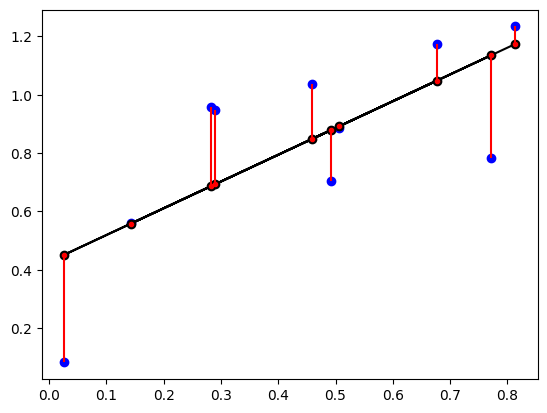

In [4]:
X_example, y_example = generate_random_data()
graph_error_bars(X_example, y_example)

# Evaluating Linear Regressions

With regression models, we no longer use accuracy to evaluate models like we did with classification. Instead, we use R2, also known as the coefficient of determination. R2 (or $R^2$) describes the proportion of variation in dependent variable that is predictable from the independent variables. We can think of it as correlation (R) squared, so it will range from 0 to 1 and we want it to be as close to 1 as possible. 

The context of your model will determine whether the R2 is "good enough" or not. We will circle back to improving R2 after we've see more models. Let's focus on creating linear regressions from a Sci-Kit Learn toy data set. 

## Code for Simple Linear Regression

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

def extract_first_feature(sk_toy_dataset):
    first_feature_predictor_variable = np.array([sk_toy_dataset.data[index][0] for index in range(len(sk_toy_dataset.data))]).reshape(-1, 1)
    first_feature_predictor_variable_name = sk_toy_dataset.feature_names[0]
    target_variable = sk_toy_dataset.target
    return [first_feature_predictor_variable, target_variable, first_feature_predictor_variable_name]

def graph_simple_linear_regression(X, y, X_label):
    X_train_1f, X_test_1f, y_train_1f, y_test_1f = train_test_split(X, y, test_size=0.2)

    # Create a decision tree classifier
    reg_lin_1f = LinearRegression()
    reg_lin_1f.fit(X_train_1f, y_train_1f)

    # Make predictions
    predictions_1f = reg_lin_1f.predict(X_test_1f)

    # Evaluate coefficient of determination
    r2_1f = r2_score(y_test_1f, predictions_1f)
    print("Linear Regression R2:", f'{int(round(r2_1f, 2)*100)}%')
    print("Linear Regression R:", f'{round(np.sqrt(r2_1f), 2)}')

    plt.scatter(X_train_1f, y_train_1f)
    # These labels assume diabetes sk-learn toy dataset
    plt.title(f'Diabetes progress by ')
    plt.xlabel(f'{X_label}')
    plt.ylabel('Quantitative Measure of Diabetes Progress')
    plt.show()

## Simple Linear Regression Example

Linear Regression R2: 5%
Linear Regression R: 0.21


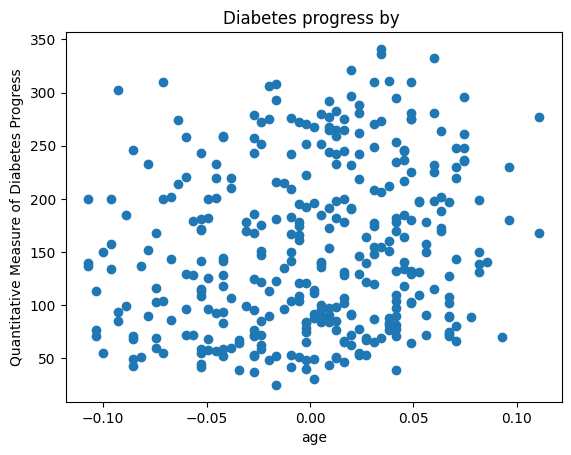

In [10]:
from sklearn.datasets import load_diabetes

diabetes_sk_toy = load_diabetes()
X, y, X_label = extract_first_feature(diabetes_sk_toy)
graph_simple_linear_regression(X, y, X_label)

Each time we run the regression, we'll get a slightly different result as we switch which data the regression is trained on. However all have extremely low R2 (usually between 0% and 5%). This matches what we see visually since the data does not appear to follow a linear relationship. 

This tells us that just `age` is not a good predictor of diabetes progress. We need more features to accurately predict the disease's progress.

You may be wondering "How is age a decimal??" If we look at diabetes.DESCR, we get our answer: 

> Note: Each of these 10 feature variables have been mean centered and scaled by the standard deviation times the square root of `n_samples` (i.e. the sum of squares of each column totals 1). 

This process is referred to as *standardizing* and is important when it comes to comparing features in a regression. We leave how to appropriately standardize data for a future lesson.

Rather than writing the regression with just the first predictor variable, let's see how R2 changes when we include all predictors. 

## Code for Full Linear Regression

In [11]:
# import necessary functions from sklearn
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
import numpy as np

def run_full_linear_regression(sk_toy_dataset):
    # This time, we use all predictor variables
    X_train, X_test, y_train, y_test = train_test_split(sk_toy_dataset.data, sk_toy_dataset.target, test_size=0.2)

    # Create a linear regression with the training data
    reg_lin = LinearRegression()
    reg_lin.fit(X_train, y_train)

    # Make predictions with the test data
    predictions = reg_lin.predict(X_test)

    # Evaluate coefficient of determination (R2)
    r2 = r2_score(y_test, predictions)
    print("Linear Regression R2:", f'{int(round(r2, 2)*100)}%')
    print("Linear Regression R:", f'{round(np.sqrt(r2), 2)}')

## Example Linear Regression

In [15]:
# Load the diabetes dataset
diabetes_sk_toy = load_diabetes()

run_full_linear_regression(diabetes_sk_toy)

Linear Regression R2: 51%
Linear Regression R: 0.71


A huge improvement! The R2 hovers around 0.5 when we use all predictor variables. This tells us the predictor variables account for about 50% of the variation in the response variable. In the context of diabetes, this tells us a large portion of the variation is unaccounted for (and so this would be a poor R2 score). 

### Visualizing Linear Regression

Since there are 10 predictor variables, this would require an 11d visualization (which we cannot do). Instead it is common to see a pair plot to consider how each predictor variable interacts with another. The final column/row is the target, letting us see the relationship of each predictor with the response variable. 

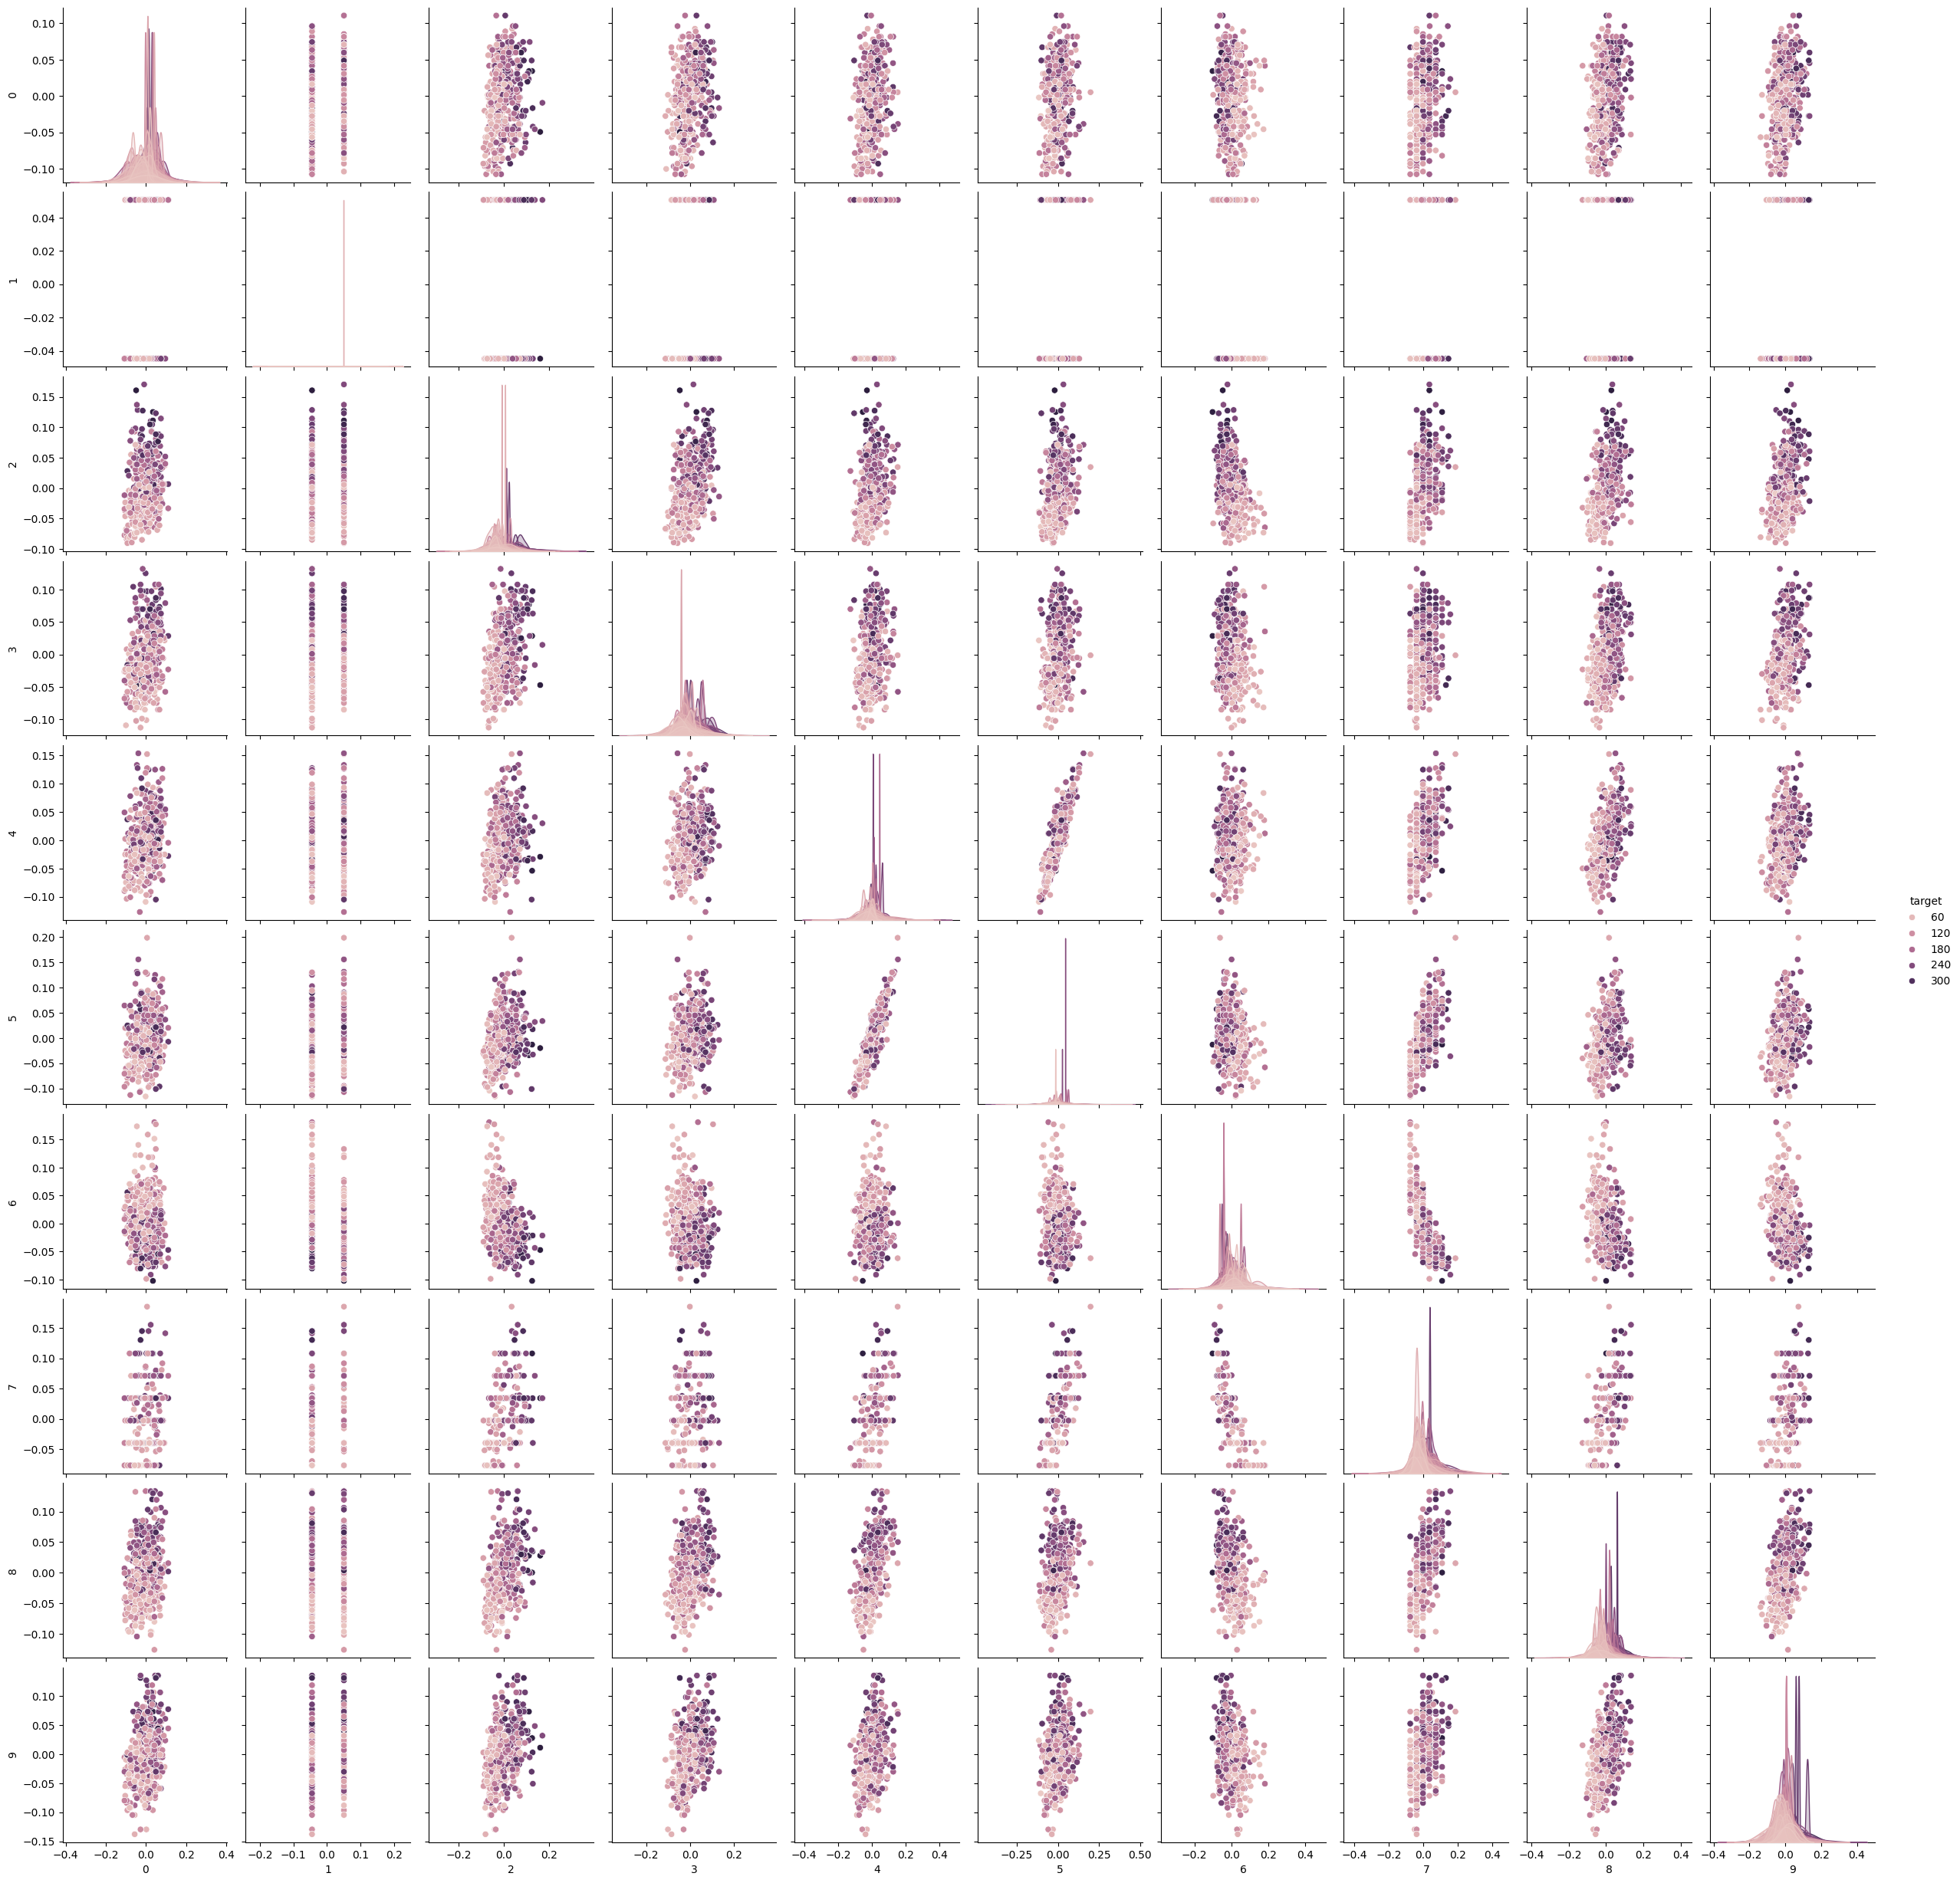

In [20]:
import pandas as pd
import seaborn as sns

# Seaborn wants a Pandas dataframe, so we convert our predictor variables into a DataFrame and attach the response variable as a new column
diabetes_df = pd.DataFrame(diabetes_sk_toy.data)
diabetes_df['target'] = pd.Series(diabetes_sk_toy.target)

sns.pairplot(diabetes_df, hue='target')

Reading this can be tough! We will leave interpreting the Pair Plot for a later lesson. 